Runtime Context 是一种依赖注入机制：调用者在运行开始时把用户身份、租户信息、权限或外部服务连接传给 Agent，节点、中间件和工具在执行时再从 Runtime 读取。

它解决的是三个工程问题：
- 避免把用户 ID、数据库连接等信息硬编码进工具。
- 同一个 Agent 可以安全地服务不同用户和租户。
- 工具的业务参数只保留真正需要模型填写的内容。

Context 中的数据默认不会自动发给大模型；只有代码主动读取并把内容加入提示词或工具结果时，模型才会看到它。

例如，在系统中用户通常会先登录，然后访问agent，我们就可以把登录用户信息存入Context，在Agent内部的Middleware或Tool旧能很方便的通过runtime.context获取用户信息。而这个用户信息并不会让模型看到，也不需要作为参数让模型传递，纯粹是Agent内部信息。

In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# 字典key是租户tenant_id，字典value是租户对应的user信息，也是字典。user字典的key是user_id
USER_DATABASE = {
    "school_a": {
        "u001": {"name": "虎哥", "course": "LangChain 开发指南"},
        "u002": {"name": "小明", "course": "Java开发入门"},
    },
    "school_b": {
        "u001": {"name": "涛哥", "course": "Python 入门"},
        "u002": {"name": "阿伟", "course": "VibeCoding 实战"},
    }
}

In [3]:
from dataclasses import dataclass

@dataclass(frozen=True)
class UserContext:
    """Agent运行时上下文信息"""
    tenant_id: str
    user_id: str

In [4]:
from langchain.tools import tool,ToolRuntime

@tool
def get_current_user_profile(runtime: ToolRuntime[UserContext]) -> str:
    """获取当前用户信息"""

    # 获取context
    ctx = runtime.context

    # 根据user_id和tenant_id从数据库中获取用户信息
    user_info = USER_DATABASE.get(ctx.tenant_id, {}).get(ctx.user_id)
    return (
        f"姓名：{user_info['name']}, "
        f"课程：{user_info['course']}"
    )

In [5]:
from langchain.agents import create_agent

# 创建Agent时指定context_schema
agent = create_agent(
    model="deepseek-flash",
    tools=[get_current_user_profile],
    context_schema=UserContext,  # 指定Context类型
    system_prompt="你是课程平台助手。需要用户资料时调用工具。"
)

In [6]:
from langchain.messages import HumanMessage

# 调用时通过Context传递用户信息
response = agent.invoke(
    {"messages": [HumanMessage(content="Hello, 帮我查询我正在学习的课程")]},
    context=UserContext(user_id="u001", tenant_id="school_a")
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

Hello, 帮我查询我正在学习的课程
================================== Ai Message ==================================

I'll look up your profile first.
Tool Calls:
  get_current_user_profile (call_00_Jdhpx7Njd2tf7kH3lylQ3818)
 Call ID: call_00_Jdhpx7Njd2tf7kH3lylQ3818
  Args:
================================= Tool Message =================================
Name: get_current_user_profile

姓名：虎哥, 课程：LangChain 开发指南
================================== Ai Message ==================================

虎哥你好！👋

我查到了你的资料：

- **姓名**：虎哥
- **正在学习的课程**：**LangChain 开发指南**

目前显示你正在学习这一门课程。如果你的课程列表应该包含更多内容，可能是学习记录还没有同步，或者需要用其他账号登录 —— 告诉我具体情况，我再帮你确认。

需要我帮你了解这门课程的哪些内容吗？比如学习路线、核心概念或实战示例？


State,它是Agent的短期记忆，存储当前会话的历史消息、任务状态等信息。

我们之前学习短期记忆时使用的是默认的AgentState，其中只包含会话的历史消息（messages），本节开始我们学习如何自定义AgentState，记录除了历史消息以外的其他信息。

In [7]:
from langchain.agents import AgentState

# 定义自定义State结构
class CustomState(AgentState):
    """Agent的任务状态"""
    model_call_count: int  # 模型调用次数

In [8]:
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command
from langchain.messages import ToolMessage


@tool
def update_model_call_count(runtime: ToolRuntime):
    """A tool that count model call """

    # 获取state中的数据
    count = runtime.state.get("model_call_count", 0)
    print("model_call_count:", count)

    # 更新State中的数据
    update= {
        "model_call_count": count + 1, # 更新count值
        "messages": [ # 工具执行结束必须返回一条ToolMessage
            ToolMessage(
                content="Successfully updated agent state",
                tool_call_id=runtime.tool_call_id
            )
        ]
    }

    return Command(update=update)

In [10]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

agent = create_agent(
    "deepseek-flash",
    tools=[update_model_call_count],
    state_schema=CustomState,  # 告诉Agent使用自定义的state
    checkpointer=InMemorySaver(),
    system_prompt="你是AI助手，你需要调用工具记录模型调用次数"
)

In [11]:
config = {"configurable": {"thread_id": "1"}}
response = agent.invoke(
    {"messages": [HumanMessage(content="Hi,我是虎哥")]},
    config
)

for message in response['messages']:
    message.pretty_print()


response = agent.invoke(
    {"messages": [HumanMessage(content="还记得我是谁吗")]},
    config
)

for message in response['messages']:
    message.pretty_print()

model_call_count: 0
================================ Human Message =================================

Hi,我是虎哥
================================== Ai Message ==================================
Tool Calls:
  update_model_call_count (call_00_8mteVywlMixLspCKjJko5715)
 Call ID: call_00_8mteVywlMixLspCKjJko5715
  Args:
================================= Tool Message =================================
Name: update_model_call_count

Successfully updated agent state
================================== Ai Message ==================================

你好，虎哥！很高兴见到你 👋 有什么我可以帮你的吗？
model_call_count: 1
================================ Human Message =================================

Hi,我是虎哥
================================== Ai Message ==================================
Tool Calls:
  update_model_call_count (call_00_8mteVywlMixLspCKjJko5715)
 Call ID: call_00_8mteVywlMixLspCKjJko5715
  Args:
================================= Tool Message =================================
Name: update_model_call_count

Succ

store是LangChain提供的长期记忆机制，用于在不同会话间共享数据。例如：模型以外的数据、用户偏好等。

例如，同一位用户可能先在 thread-a 中告诉 Agent“我喜欢代码示例优先”，几天后又在 thread-b 中开始新的课程咨询。
如果这条偏好只放在 State 中，新 thread 无法自动读取；把它写入 Store 后，两个 thread 都可以访问。

LangChain提供了多种Store的实现方式，例如：
- InMemoryStore
- PostgresStore
- RedisStore

以InMemoryStore为例来学习。
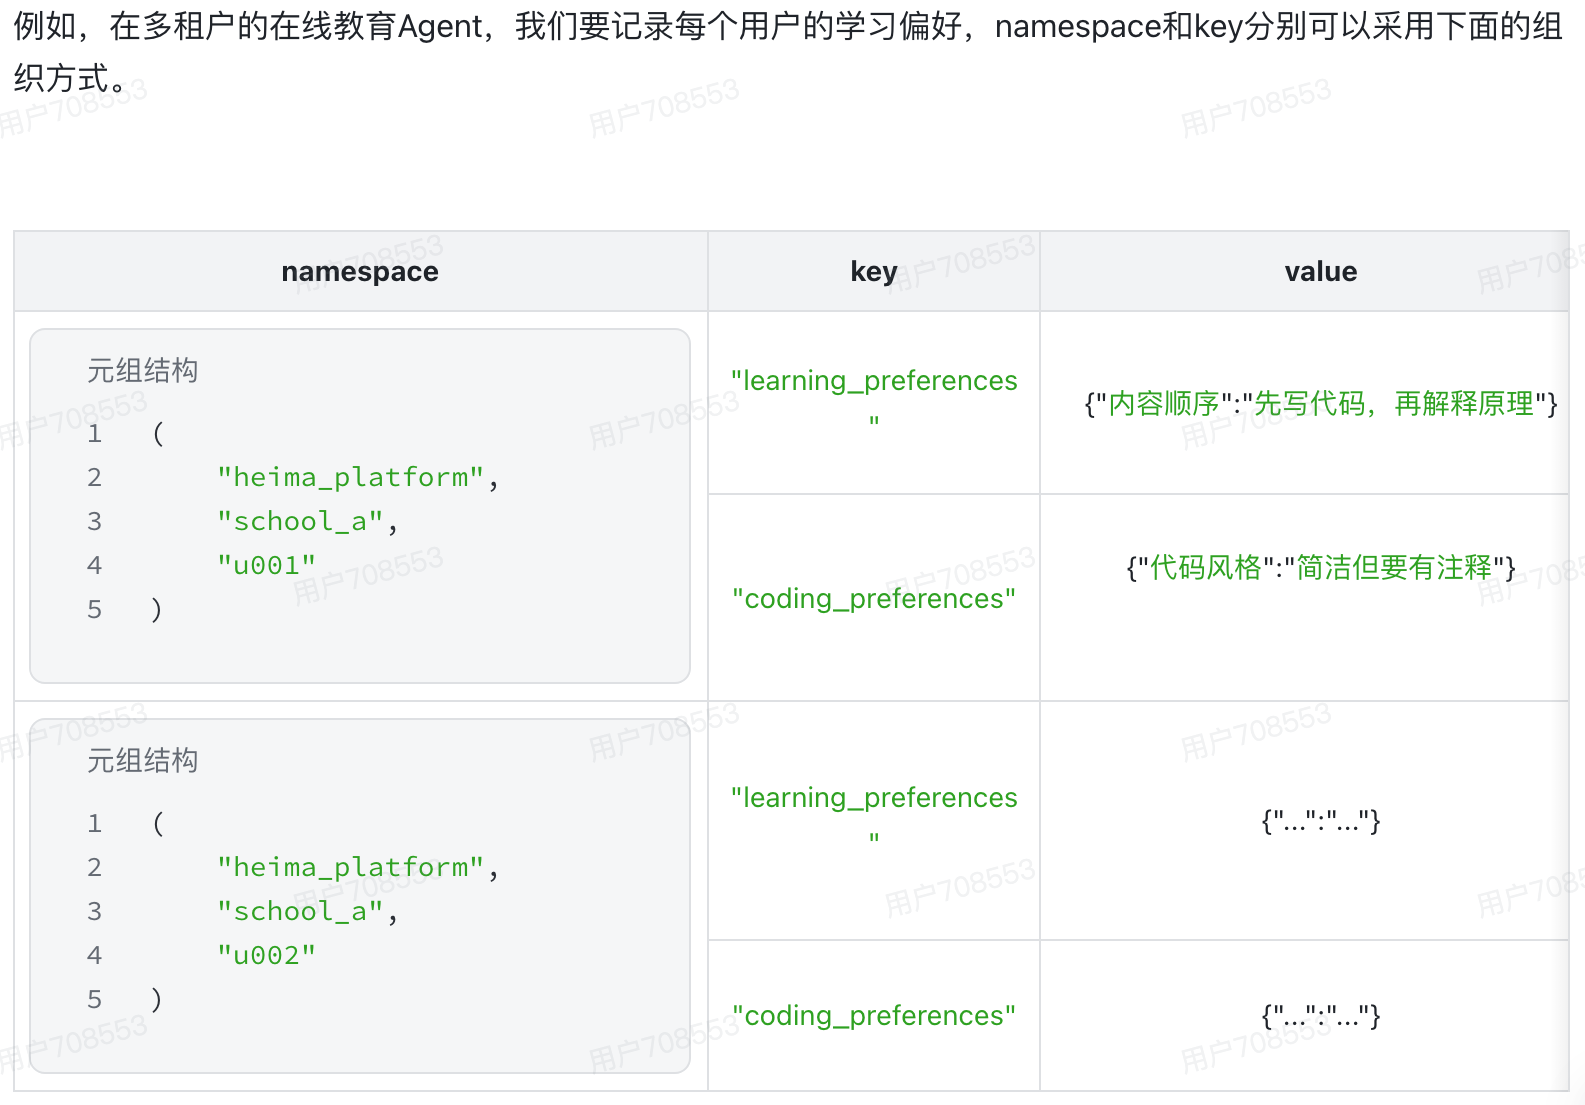

In [12]:
from langgraph.store.memory import InMemoryStore

# ==================== 1. 创建Store ====================
store = InMemoryStore()

In [22]:
from langchain.tools import ToolRuntime, tool


# 定义方法，根据Context中的tenant_id和user_id拼接得到namespace
def preference_namespace(ctx: UserContext) -> tuple[str, ...]:
    return (
        "heima_platform",
        ctx.tenant_id,
        ctx.user_id
    )
# 定义固定的key
key = "learning_preferences"

@tool
def save_learning_preference(
    preference_name: str,
    preference_value: str,
    runtime: ToolRuntime[UserContext],
) -> str:
    """保存当前用户的长期学习偏好。"""

    # 通过上下文中的tenant_id和user_id来构建namespace
    namespace = preference_namespace(runtime.context)

    # 通过namespace和key来读取用户偏好, 返回结果item.value是dict格式
    item = runtime.store.get(namespace, key)
    preferences = dict(item.value) if item else {}

    # 记录本次要保存的用户偏好
    preferences[preference_name] = preference_value

    # 保存到Store中
    runtime.store.put(namespace, key, preferences)

    return f"已保存偏好：{preference_name}={preference_value}"


@tool
def get_learning_preferences(
    runtime: ToolRuntime[UserContext],
) -> str:
    """读取当前用户的长期学习偏好。"""

    namespace = preference_namespace(runtime.context)
    item = runtime.store.get(namespace, key)

    if item is None:
        return "当前用户还没有保存学习偏好"

    return f"当前学习偏好：{item.value}"

In [23]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore


checkpointer = InMemorySaver()
store = InMemoryStore()

agent = create_agent(
    model="deepseek-flash",
    tools=[
        get_current_user_profile,
        save_learning_preference,
        get_learning_preferences,
    ],
    context_schema=UserContext,
    checkpointer=checkpointer,
    store=store,
    system_prompt=(
        "你是课程平台助手。"
        "涉及用户资料时调用资料工具，"
        "涉及长期学习偏好或给用户讲解代码时调用偏好工具。"
    ),
)

In [24]:
context = UserContext(
    user_id="u001",
    tenant_id="school_a",
)

result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "记住：我喜欢先看代码，再看原理",
            }
        ]
    },
    config={"configurable": {"thread_id": "thread-a"}},
    context=context,
)
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

记住：我喜欢先看代码，再看原理
================================== Ai Message ==================================
Tool Calls:
  save_learning_preference (call_00_jW9z60ocfxKExkc9kSFW2940)
 Call ID: call_00_jW9z60ocfxKExkc9kSFW2940
  Args:
    preference_name: 讲解顺序偏好
    preference_value: 先看代码示例，再看原理讲解
================================= Tool Message =================================
Name: save_learning_preference

已保存偏好：讲解顺序偏好=先看代码示例，再看原理讲解
================================== Ai Message ==================================

已经记下啦 ✅

**偏好：先看代码示例，再看原理讲解**

以后我讲解知识点或示例时，会按这个顺序来：
1. 先给出可运行的代码（或核心代码片段），让你先看“长什么样、怎么用”
2. 再展开背后的原理、设计动机和细节注意事项

如果你某次想反过来（比如先要概念框架），直接说一句“这次先讲原理”就行，我会临时切换。
